# DeepShield - Audio Deepfake Detection
### Data analysis, model preparation and CUDA training  |  Baseline: Log-Mel spectrogram + CNN

**Task:** classify a speech clip as **REAL** (bonafide) or **SYNTHETIC** (spoofed / TTS / voice-conversion).
**Dataset:** ASVspoof 2019 - Logical Access (LA).  **Hardware:** NVIDIA GPU with CUDA + FP16 mixed precision.

| # | Section |
|---|---|
| 1 | Environment and GPU check |
| 2 | Dataset overview |
| 3 | Feature extraction (waveform -> log-Mel / MFCC) |
| 4 | Data loaders |
| 5 | Model architecture |
| 6 | Training on CUDA |
| 7 | Evaluation (dev + eval with unseen attacks) |
| 8 | Summary and next steps |

## 1. Environment and GPU check

In [3]:
%pip install soundfile

  Using cached soundfile-0.14.0-py2.py3-none-win_amd64.whl.metadata (18 kB)
Using cached soundfile-0.14.0-py2.py3-none-win_amd64.whl (1.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
%matplotlib inline
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "config.yaml").exists() and (p / "deepshield").is_dir():
            return p
    raise FileNotFoundError("Open this notebook from inside the DeepShield project folder (the one with config.yaml).")


ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

from deepshield.config import load_config
from deepshield.data.audio import load_audio, fix_length, peak_normalize
from deepshield.data.dataset import make_loader
from deepshield.features.frontend import LogMel, MFCC
from deepshield.models.baseline_cnn import MelCNN
from deepshield.engine import set_seed, train_one_epoch, predict
from deepshield.metrics import classification_metrics, compute_eer, per_attack_eer

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

cfg = load_config()
DATA_ROOT, MANIFESTS = cfg.root_path, cfg.manifest_path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Project root : {ROOT}")
print(f"Dataset root : {DATA_ROOT}")
print(f"Manifests    : {MANIFESTS}")
print("-" * 64)
print(f"PyTorch      : {torch.__version__}   (built for CUDA {torch.version.cuda})")
if DEVICE.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU          : {p.name}")
    print(f"VRAM         : {p.total_memory / 1024**3:.1f} GB    compute capability {p.major}.{p.minor}")
    print(f"cuDNN        : {torch.backends.cudnn.version()}")
    print("Training on  : CUDA with FP16 mixed precision (AMP)")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA is not available - running on CPU (training will be very slow).")
assert (MANIFESTS / "train.csv").exists(), "Manifests missing - run scripts/01_build_manifests.py first."

Project root : C:\Study\study\Major 1\deepshield_step1\deepshield
Dataset root : C:\Study\study\Major 1\archive (1)\LA\LA
Manifests    : C:\Study\study\Major 1\deepshield_step1\deepshield\manifests
----------------------------------------------------------------
PyTorch      : 2.7.1+cu118   (built for CUDA 11.8)
GPU          : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM         : 6.0 GB    compute capability 8.9
cuDNN        : 90100
Training on  : CUDA with FP16 mixed precision (AMP)


In [5]:
# ---------------- experiment settings (edit here) ----------------
TRAIN        = True    # False -> skip training and load an existing checkpoint (quick demo)
EPOCHS       = 15
BATCH_SIZE   = 32
LR           = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE     = 5       # early stopping on dev EER
NUM_WORKERS  = 4       # data-loading processes
USE_AMP      = True    # FP16 mixed precision on the GPU
SEED         = 42

AMP = USE_AMP and DEVICE.type == "cuda"
OUT = ROOT / "outputs" / "notebook_run"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
CKPT = OUT / "best.pt"
FALLBACK_CKPT = ROOT / "outputs" / "baseline_cnn" / "best.pt"  # used if TRAIN=False and no notebook checkpoint yet
set_seed(SEED)
print("Outputs will be saved to:", OUT)

Outputs will be saved to: C:\Study\study\Major 1\deepshield_step1\deepshield\outputs\notebook_run


## 2. Dataset overview
ASVspoof 2019 LA is split by **speaker**: train (20 speakers), dev, and eval (67 speakers). Train/dev contain spoofing attacks
**A01-A06** ("known"); the **eval** set mostly contains **A07-A19** - algorithms the model never sees during training
(A16 and A19 are the same algorithms as A04 and A06). Eval performance therefore measures *generalisation to unseen deepfake generators*.

,utterances,REAL (bonafide),SYNTHETIC (spoof),spoof : real ratio,speakers,attack types,mean duration (s)
train,25380.0,2580.0,22800.0,8.84,20.0,6.0,3.43
dev,24844.0,2548.0,22296.0,8.75,20.0,6.0,3.48
eval,71237.0,7355.0,63882.0,8.69,67.0,13.0,3.11


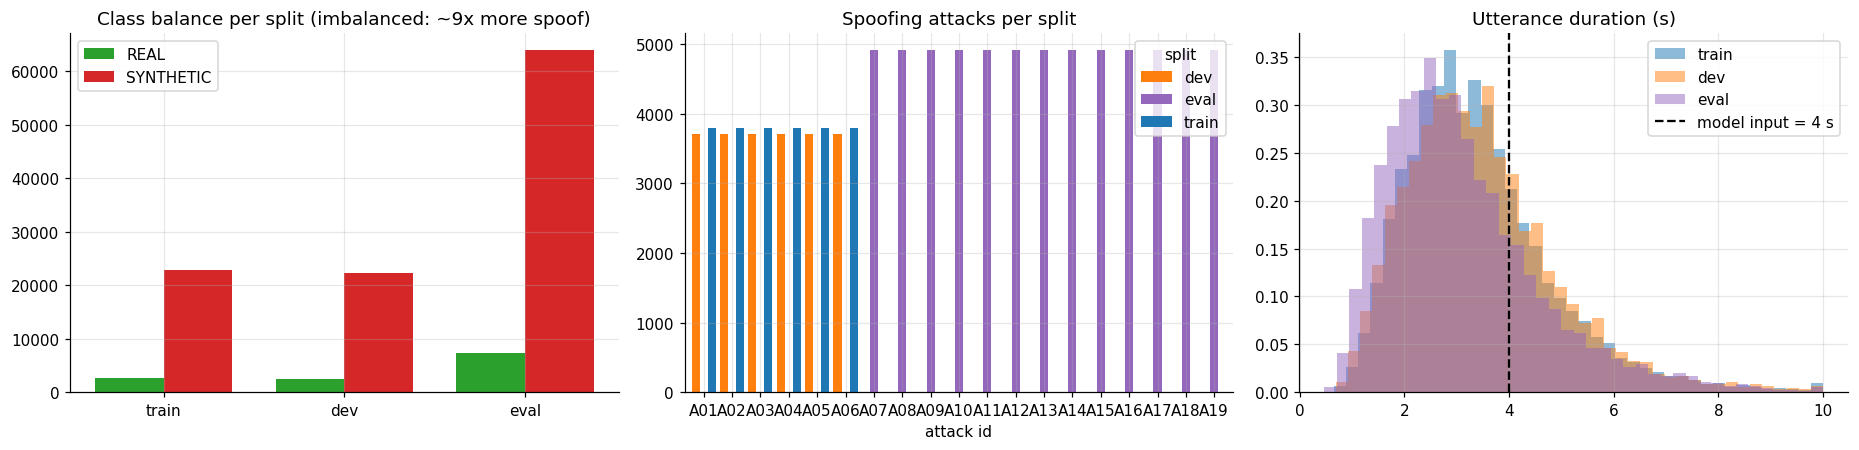

In [6]:
train_df, dev_df, eval_df = [pd.read_csv(MANIFESTS / f"{s}.csv") for s in ("train", "dev", "eval")]
splits = {"train": train_df, "dev": dev_df, "eval": eval_df}

summary = pd.DataFrame({
    name: {
        "utterances": len(d),
        "REAL (bonafide)": int((d.label == 0).sum()),
        "SYNTHETIC (spoof)": int((d.label == 1).sum()),
        "spoof : real ratio": round((d.label == 1).sum() / max((d.label == 0).sum(), 1), 2),
        "speakers": d.speaker.nunique(),
        "attack types": d[d.label == 1].attack.nunique(),
        "mean duration (s)": round(d.duration.mean(), 2),
    } for name, d in splits.items()
}).T
display(summary)

colors = {"train": "tab:blue", "dev": "tab:orange", "eval": "tab:purple"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

x, w = np.arange(3), 0.38
ax[0].bar(x - w / 2, [(d.label == 0).sum() for d in splits.values()], w, label="REAL", color="tab:green")
ax[0].bar(x + w / 2, [(d.label == 1).sum() for d in splits.values()], w, label="SYNTHETIC", color="tab:red")
ax[0].set_xticks(x, list(splits)); ax[0].set_title("Class balance per split (imbalanced: ~9x more spoof)"); ax[0].legend()

att = pd.concat([d[d.label == 1].assign(split=n) for n, d in splits.items()])
pv = att.groupby(["attack", "split"]).size().unstack("split").fillna(0)
pv.plot(kind="bar", ax=ax[1], color=[colors[c] for c in pv.columns], width=0.85)
ax[1].set_title("Spoofing attacks per split"); ax[1].set_xlabel("attack id"); ax[1].tick_params(axis="x", rotation=0)

for n, d in splits.items():
    ax[2].hist(d.duration.clip(upper=10), bins=40, alpha=0.5, label=n, color=colors[n], density=True)
ax[2].axvline(cfg.segment_seconds, color="k", ls="--", label=f"model input = {cfg.segment_seconds:.0f} s")
ax[2].set_title("Utterance duration (s)"); ax[2].legend()
plt.tight_layout(); fig.savefig(FIG / "dataset_overview.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Feature extraction
Raw 16 kHz audio is cropped / padded to a fixed 4 s window and peak-normalised. The front-ends run **on the GPU inside the model**
(`torch.stft` -> mel filter-bank -> log), so no spectrogram files are stored on disk.
* **Log-Mel spectrogram** (80 bands, 25 ms window, 10 ms hop): the "image" fed to the CNN.
* **MFCC** (20 coefficients): compact cepstral features - used by the acoustic branch of the final fusion model.

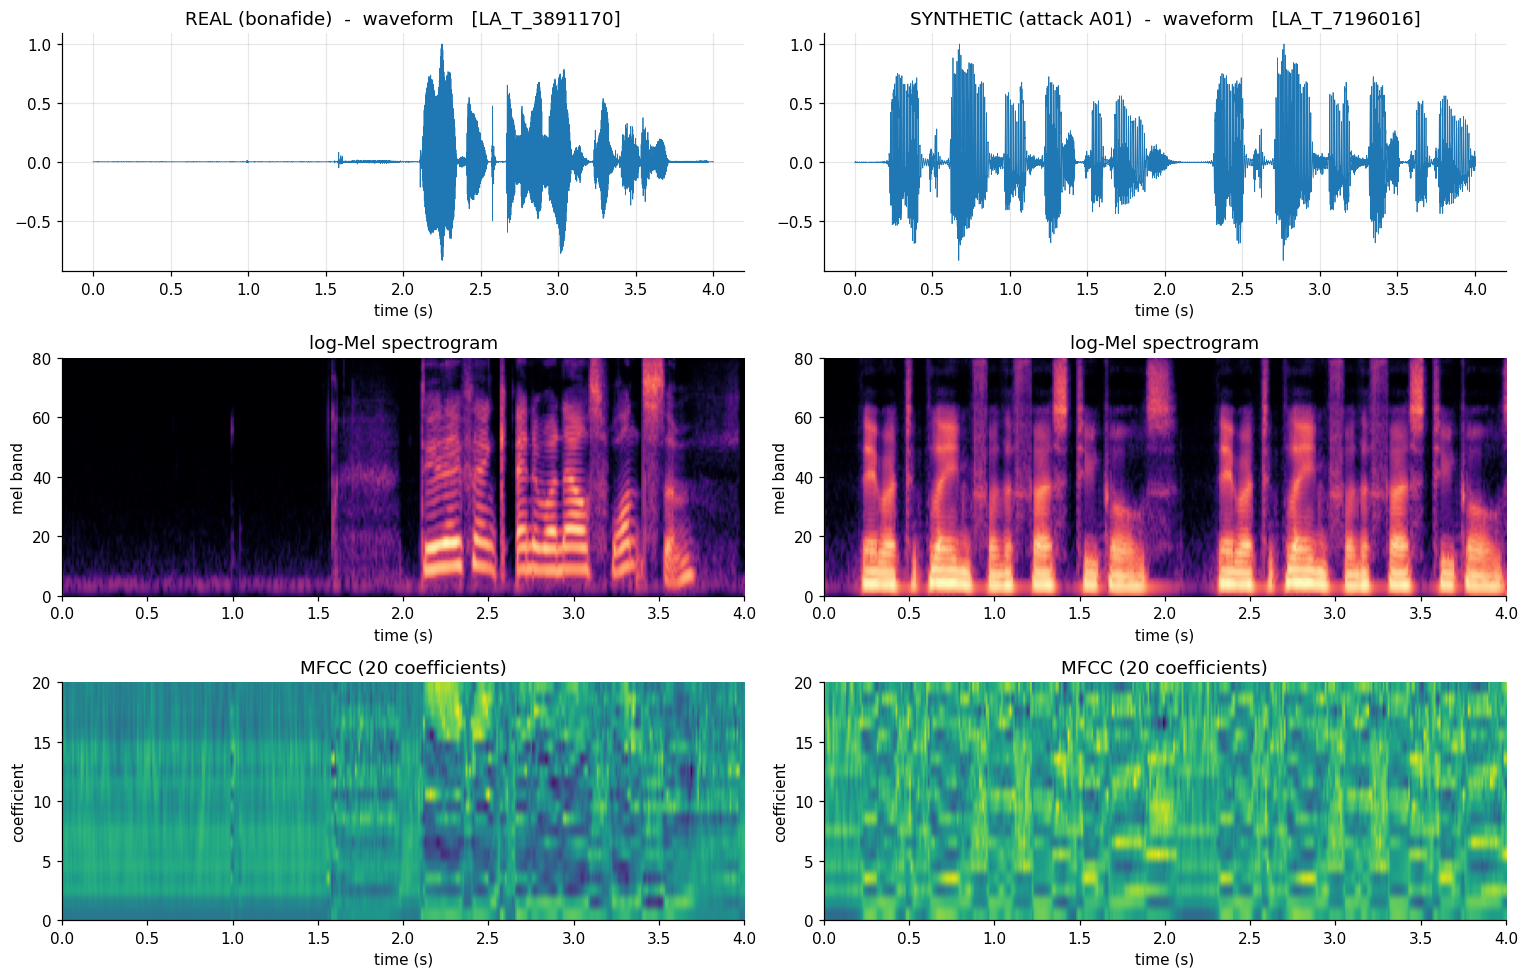

In [7]:
real_row  = train_df[train_df.label == 0].sample(1, random_state=SEED).iloc[0]
spoof_row = train_df[train_df.label == 1].sample(1, random_state=SEED).iloc[0]
logmel_fe, mfcc_fe = LogMel(), MFCC(deltas=False)


def prep(row):
    x = load_audio(DATA_ROOT / row.rel_path, cfg.sample_rate)
    return peak_normalize(fix_length(x, cfg.segment_samples, "center"))


fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for col, (row, title) in enumerate([(real_row, "REAL (bonafide)"), (spoof_row, f"SYNTHETIC (attack {spoof_row.attack})")]):
    x = prep(row); t = torch.from_numpy(x)[None]
    with torch.no_grad():
        lm, mf = logmel_fe(t)[0].numpy(), mfcc_fe(t)[0].numpy()
    axes[0, col].plot(np.arange(len(x)) / cfg.sample_rate, x, lw=0.5, color="tab:blue")
    axes[0, col].set(title=f"{title}  -  waveform   [{row.utt_id}]", xlabel="time (s)")
    axes[1, col].imshow(lm, origin="lower", aspect="auto", extent=[0, cfg.segment_seconds, 0, lm.shape[0]], cmap="magma")
    axes[1, col].set(title="log-Mel spectrogram", xlabel="time (s)", ylabel="mel band"); axes[1, col].grid(False)
    axes[2, col].imshow(mf, origin="lower", aspect="auto", extent=[0, cfg.segment_seconds, 0, mf.shape[0]], cmap="viridis")
    axes[2, col].set(title="MFCC (20 coefficients)", xlabel="time (s)", ylabel="coefficient"); axes[2, col].grid(False)
plt.tight_layout(); fig.savefig(FIG / "features_real_vs_spoof.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Data loaders
* Training batches use a **weighted sampler**: REAL clips are oversampled so each batch is about 50 % REAL / 50 % SYNTHETIC (the raw data is ~90 % spoof).
* Training uses a **random 4 s crop**; dev / eval use a deterministic centre crop. Shorter clips are repeat-padded.

In [8]:
common = dict(sr=cfg.sample_rate, segment_samples=cfg.segment_samples)
train_loader = make_loader(MANIFESTS / "train.csv", DATA_ROOT, train=True,  batch_size=BATCH_SIZE,     num_workers=NUM_WORKERS, **common)
dev_loader   = make_loader(MANIFESTS / "dev.csv",   DATA_ROOT, train=False, batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, **common)
eval_loader  = make_loader(MANIFESTS / "eval.csv",  DATA_ROOT, train=False, batch_size=BATCH_SIZE * 2, num_workers=NUM_WORKERS, **common)
print(f"train: {len(train_loader.dataset):,} clips -> {len(train_loader)} steps/epoch | "
      f"dev: {len(dev_loader.dataset):,} | eval: {len(eval_loader.dataset):,}")

shares = []
it = iter(train_loader)
for _ in range(5):
    shares.append(round(next(it)["label"].mean().item(), 2))
del it
print("Share of SYNTHETIC clips in 5 training batches:", shares, "(raw training data: 0.90)")

train: 25,380 clips -> 793 steps/epoch | dev: 24,844 | eval: 71,237
Share of SYNTHETIC clips in 5 training batches: [0.31, 0.44, 0.56, 0.5, 0.47] (raw training data: 0.90)


## 5. Model architecture
`waveform [B, 64000]` -> **log-Mel** (GPU) -> **SpecAugment** (train only) -> **4 x [Conv-BN-ReLU x2 + MaxPool]** (32-64-128-256 channels)
-> **mean + max pooling** -> MLP head -> **1 logit** (probability of SYNTHETIC after a sigmoid). Loss: binary cross-entropy.

In [9]:
model = MelCNN().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params / 1e6:.2f} M (all trainable)\n")
print(model)

Parameters: 1.24 M (all trainable)

MelCNN(
  (frontend): LogMel()
  (specaug): SpecAugment()
  (cnn): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e

In [10]:
# tensor shapes through the network
model.eval()
with torch.no_grad():
    x = torch.randn(2, cfg.segment_samples, device=DEVICE)
    f = model.frontend(x)
    print(f"{'waveform':<18}{tuple(x.shape)}")
    print(f"{'log-Mel':<18}{tuple(f.shape)}")
    h = f.unsqueeze(1)
    for i, blk in enumerate(model.cnn, 1):
        h = blk(h)
        print(f"{'conv block ' + str(i):<18}{tuple(h.shape)}")
    emb = torch.cat([h.mean(dim=(2, 3)), h.amax(dim=(2, 3))], dim=1)
    print(f"{'pooled embedding':<18}{tuple(emb.shape)}")
    print(f"{'logit':<18}{tuple(model.head(emb).shape)}")

waveform          (2, 64000)
log-Mel           (2, 80, 401)
conv block 1      (2, 32, 40, 200)
conv block 2      (2, 64, 20, 100)
conv block 3      (2, 128, 10, 50)
conv block 4      (2, 256, 5, 25)
pooled embedding  (2, 512)
logit             (2, 1)


## 6. Training on CUDA
* Optimiser **AdamW** with a **one-cycle** learning-rate schedule, **FP16 mixed precision** and gradient clipping.
* After every epoch the model is validated on the **dev** set; the checkpoint with the **lowest dev EER** is kept and training stops early if it does not improve.
* The **eval** set (unseen attacks) is **never** used for training or model selection.

*Set `TRAIN = False` in the settings cell to skip training and load a saved checkpoint.*

Epoch 15/15 | train loss 0.0035 | dev EER 0.07% | best dev EER 0.07% | 85s/epoch


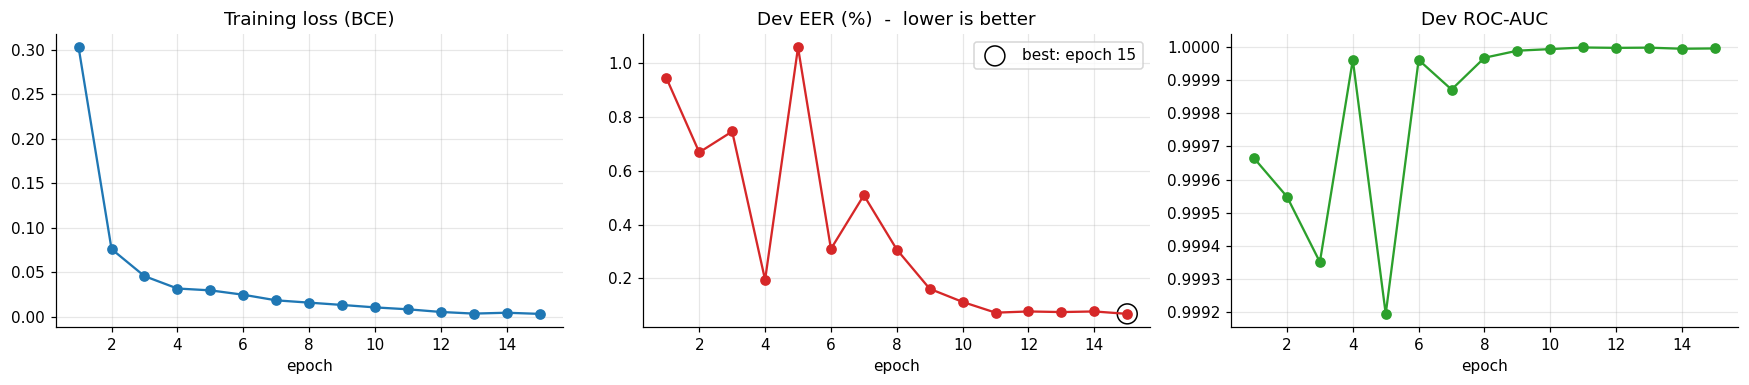

,epoch,train_loss,dev_eer,dev_auc,dev_f1,dev_bal_acc,lr,seconds
0,1,0.3026,0.0094,0.9997,0.9972,0.9866,0.0004,210.4
1,2,0.0763,0.0067,0.9995,0.9874,0.9858,0.0010,88.8
2,3,0.0459,0.0075,0.9994,0.9624,0.6586,0.0010,83.1
3,4,0.0320,0.0019,1.0000,0.9991,0.9976,0.0010,110.4
4,5,0.0299,0.0106,0.9992,0.9439,0.9456,0.0009,134.7
5,6,0.0250,0.0031,1.0000,0.9861,0.9863,0.0008,128.2
6,7,0.0187,0.0051,0.9999,0.9980,0.9943,0.0007,124.6
7,8,0.0161,0.0031,1.0000,0.9992,0.9970,0.0006,121.8
8,9,0.0136,0.0016,1.0000,0.9995,0.9972,0.0005,76.1
9,10,0.0108,0.0011,1.0000,0.9978,0.9978,0.0003,77.1



Training finished in 29.8 min on cuda.
Peak GPU memory used: 1.53 GB


In [11]:
def plot_history(h):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot(h.epoch, h.train_loss, "o-"); ax[0].set_title("Training loss (BCE)")
    ax[1].plot(h.epoch, h.dev_eer * 100, "o-", color="tab:red"); ax[1].set_title("Dev EER (%)  -  lower is better")
    ax[2].plot(h.epoch, h.dev_auc, "o-", color="tab:green"); ax[2].set_title("Dev ROC-AUC")
    be = h.loc[h.dev_eer.idxmin()]
    ax[1].scatter([be.epoch], [be.dev_eer * 100], s=170, facecolors="none", edgecolors="k", label=f"best: epoch {int(be.epoch)}")
    ax[1].legend()
    for a in ax:
        a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()
    return fig


if TRAIN:
    set_seed(SEED)
    model = MelCNN().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    rows, best_eer, bad, t_start = [], None, 0, time.time()
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, opt, sched, scaler, DEVICE, amp=AMP)
        dev_s = predict(model, dev_loader, DEVICE, amp=AMP)
        m = classification_metrics(dev_s.label, dev_s.score)
        rows.append(dict(epoch=epoch, train_loss=loss, dev_eer=m["eer"], dev_auc=m["roc_auc"], dev_f1=m["f1"],
                         dev_bal_acc=m["balanced_accuracy"], lr=opt.param_groups[0]["lr"], seconds=round(time.time() - t0, 1)))
        hist = pd.DataFrame(rows)

        if best_eer is None or m["eer"] < best_eer:
            best_eer, bad = m["eer"], 0
            torch.save({"model": model.state_dict(), "epoch": epoch, "dev_eer": best_eer,
                        "settings": dict(EPOCHS=EPOCHS, BATCH_SIZE=BATCH_SIZE, LR=LR, SEED=SEED, AMP=AMP)}, CKPT)
        else:
            bad += 1

        clear_output(wait=True)
        print(f"Epoch {epoch}/{EPOCHS} | train loss {loss:.4f} | dev EER {m['eer'] * 100:.2f}% | "
              f"best dev EER {best_eer * 100:.2f}% | {time.time() - t0:.0f}s/epoch")
        fig_hist = plot_history(hist)
        display(hist.round(4))
        if bad >= PATIENCE:
            print(f"Early stopping: dev EER did not improve for {PATIENCE} epochs.")
            break

    hist.to_csv(OUT / "history.csv", index=False)
    fig_hist.savefig(FIG / "training_curves.png", dpi=150, bbox_inches="tight")
    CKPT_USED = CKPT
    print(f"\nTraining finished in {(time.time() - t_start) / 60:.1f} min on {DEVICE}.")
    if DEVICE.type == "cuda":
        print(f"Peak GPU memory used: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
else:
    CKPT_USED = CKPT if CKPT.exists() else FALLBACK_CKPT
    print("TRAIN = False -> using checkpoint:", CKPT_USED)
    hp = CKPT_USED.parent / "history.csv"
    if hp.exists():
        plot_history(pd.read_csv(hp))

## 7. Evaluation
Metrics: Accuracy, Precision, Recall, F1 (positive class = SYNTHETIC), ROC-AUC and **EER** (equal error rate - the standard anti-spoofing metric;
it is the error where false-accept and false-reject rates are equal, and it does not depend on a threshold).

In [12]:
ck = torch.load(CKPT_USED, map_location=DEVICE, weights_only=True)
model = MelCNN().to(DEVICE)
model.load_state_dict(ck["model"])
model.eval()
print(f"Loaded best checkpoint: epoch {ck['epoch']}  (dev EER {ck['dev_eer'] * 100:.2f}%)")

t0 = time.time()
dev_scores = predict(model, dev_loader, DEVICE, amp=AMP)
eval_scores = predict(model, eval_loader, DEVICE, amp=AMP)
n_tot = len(dev_scores) + len(eval_scores)
print(f"Scored {n_tot:,} utterances in {time.time() - t0:.0f} s  ({n_tot / (time.time() - t0):.0f} clips/s on {DEVICE})")
dev_scores.to_csv(OUT / "scores_dev.csv", index=False)
eval_scores.to_csv(OUT / "scores_eval.csv", index=False)

dm = classification_metrics(dev_scores.label, dev_scores.score)
em = classification_metrics(eval_scores.label, eval_scores.score)
em_dev_thr = classification_metrics(eval_scores.label, eval_scores.score, thr=dm["eer_threshold"])
em_eer_thr = classification_metrics(eval_scores.label, eval_scores.score, thr=em["eer_threshold"])

settings = [("dev  | threshold 0.5", dm), ("eval | threshold 0.5", em),
            ("eval | threshold calibrated on dev", em_dev_thr), ("eval | EER threshold (analysis only)", em_eer_thr)]
table = pd.DataFrame([{
    "setting": n, "threshold": m["threshold"], "accuracy": m["accuracy"], "balanced acc": m["balanced_accuracy"],
    "precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "EER (%)": m["eer"] * 100, "ROC-AUC": m["roc_auc"],
} for n, m in settings]).set_index("setting")
display(table.round(4))

Loaded best checkpoint: epoch 15  (dev EER 0.07%)


predict:   0%|          | 0/389 [00:00<?, ?it/s]

predict:   0%|          | 0/1114 [00:21<?, ?it/s]

Scored 96,081 utterances in 428 s  (224 clips/s on cuda)


,threshold,accuracy,balanced acc,precision,recall,F1,EER (%),ROC-AUC
setting,,,,,,,,
dev | threshold 0.5,0.5000,0.9994,0.9988,0.9998,0.9996,0.9997,0.0684,1.0000
eval | threshold 0.5,0.5000,0.7643,0.8668,0.9994,0.7376,0.8488,5.7473,0.9836
eval | threshold calibrated on dev,0.7910,0.7402,0.8538,0.9995,0.7107,0.8307,5.7473,0.9836
eval | EER threshold (analysis only),0.0001,0.9426,0.9425,0.9930,0.9426,0.9671,5.7473,0.9836


**How to read the table.** EER and ROC-AUC are threshold-free and measure how well the model *ranks* REAL above SYNTHETIC. Accuracy / Precision / Recall / F1
depend on the decision threshold. A large difference between the *threshold 0.5* row and the *EER threshold* row on the eval set means the model ranks clips well
but its scores shift on **unseen attacks** - this is the generalisation problem the WavLM + fusion model and the robustness training (next steps) are designed to reduce.
The "EER threshold" row uses eval labels and is shown for analysis only, not as a deployable result.

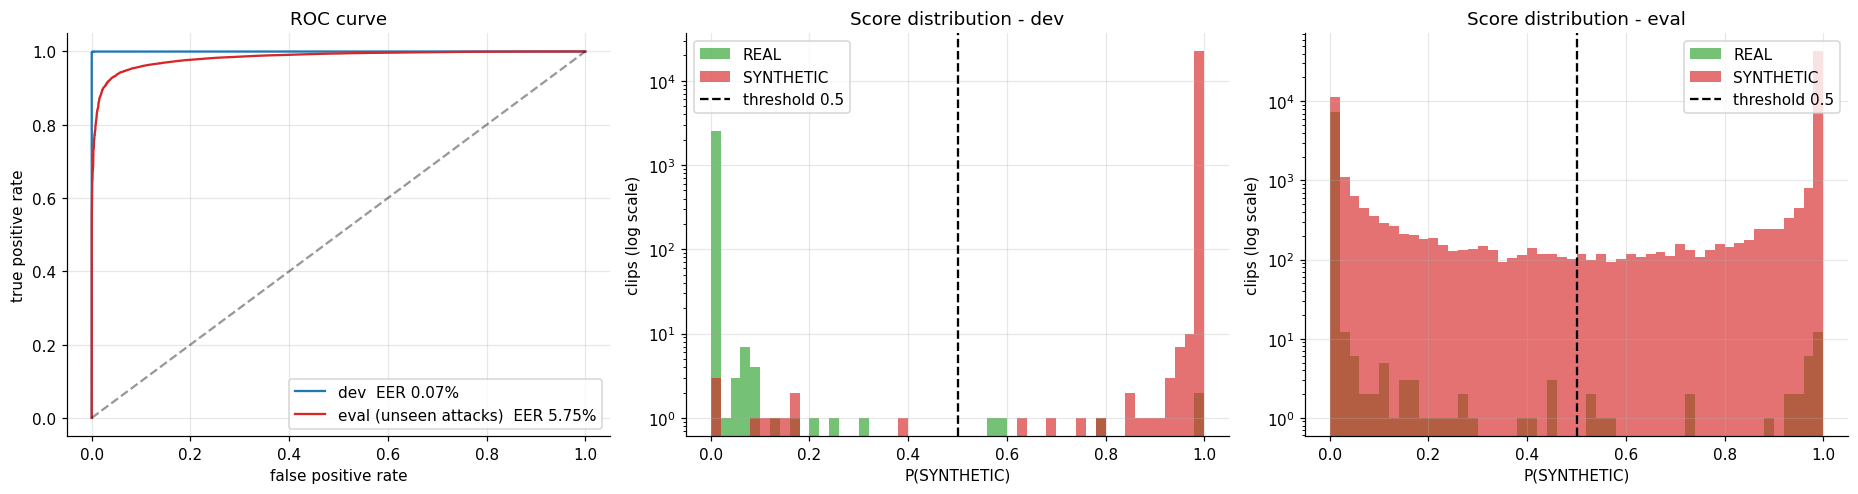

In [13]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for name, sc, col in [("dev", dev_scores, "tab:blue"), ("eval (unseen attacks)", eval_scores, "tab:red")]:
    fpr, tpr, _ = roc_curve(sc.label, sc.score)
    eer, _ = compute_eer(sc.label, sc.score)
    ax[0].plot(fpr, tpr, color=col, label=f"{name}  EER {eer * 100:.2f}%")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate"); ax[0].legend(loc="lower right")

bins = np.linspace(0, 1, 51)
for a, (name, sc) in zip(ax[1:], [("dev", dev_scores), ("eval", eval_scores)]):
    a.hist(sc[sc.label == 0].score, bins=bins, alpha=0.65, color="tab:green", label="REAL")
    a.hist(sc[sc.label == 1].score, bins=bins, alpha=0.65, color="tab:red", label="SYNTHETIC")
    a.axvline(0.5, color="k", ls="--", label="threshold 0.5")
    a.set_yscale("log"); a.set(title=f"Score distribution - {name}", xlabel="P(SYNTHETIC)", ylabel="clips (log scale)"); a.legend()
plt.tight_layout(); fig.savefig(FIG / "roc_and_score_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

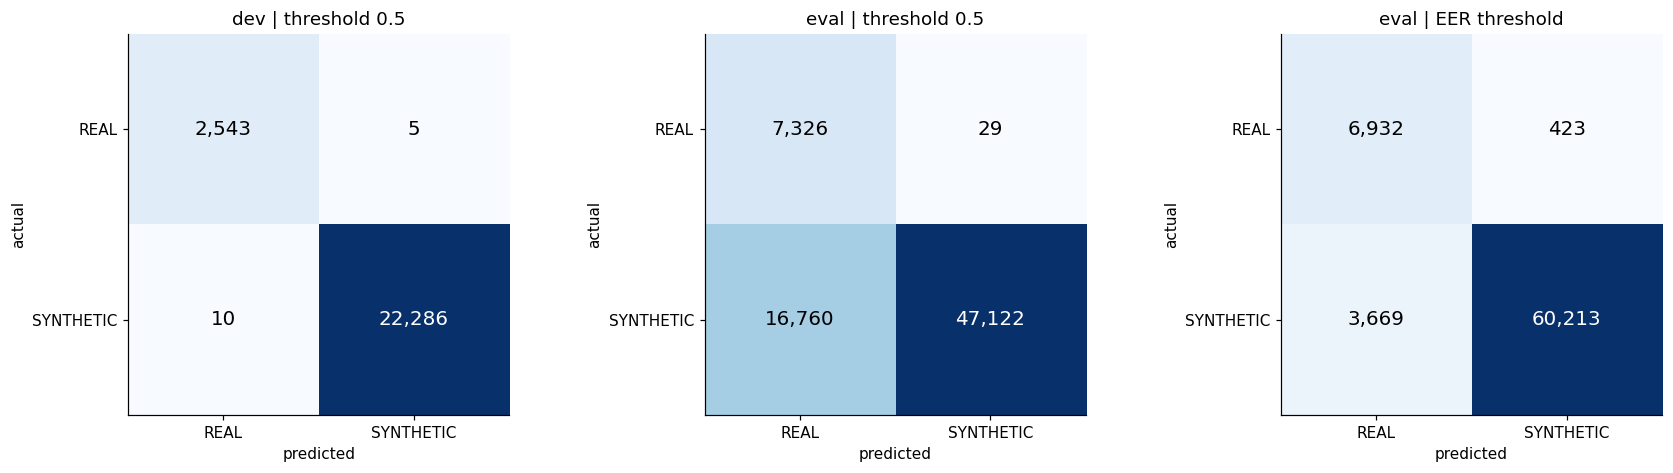

In [14]:
def draw_cm(a, m, title):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    a.imshow(cm, cmap="Blues"); a.grid(False)
    a.set_xticks([0, 1], ["REAL", "SYNTHETIC"]); a.set_yticks([0, 1], ["REAL", "SYNTHETIC"])
    a.set(title=title, xlabel="predicted", ylabel="actual")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")


fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
draw_cm(ax[0], dm, "dev | threshold 0.5")
draw_cm(ax[1], em, "eval | threshold 0.5")
draw_cm(ax[2], em_eer_thr, "eval | EER threshold")
plt.tight_layout(); fig.savefig(FIG / "confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

### Per-attack analysis (generalisation to unseen deepfake generators)
EER of *all real clips* versus *each spoofing algorithm separately*. Blue = algorithms also used in training; orange = unseen.

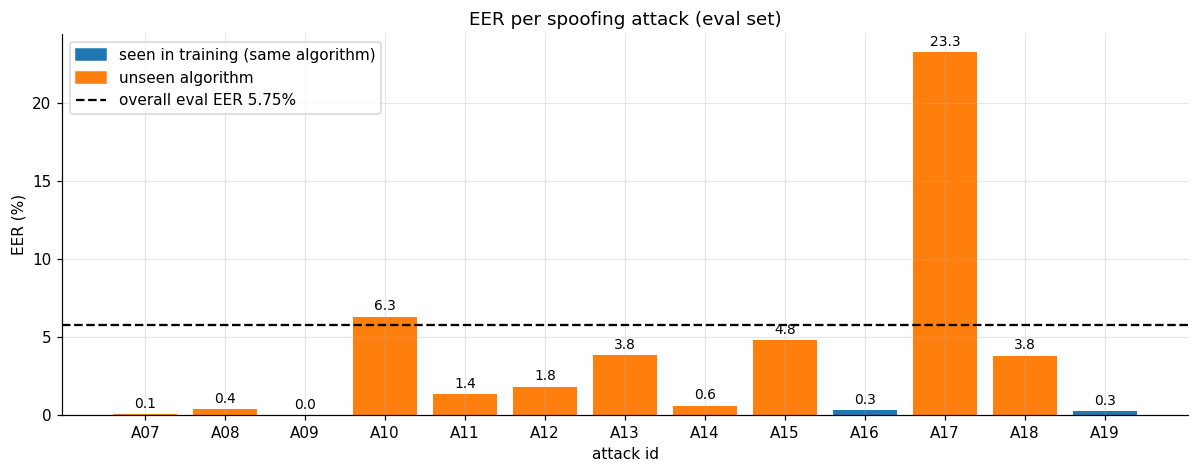

In [15]:
pa = per_attack_eer(eval_scores, eval_df)
pa_s = pd.Series(pa).sort_index() * 100
seen = {"A16", "A19"}  # same algorithms as training attacks A04 / A06
cols = ["tab:blue" if a in seen else "tab:orange" for a in pa_s.index]

fig, ax = plt.subplots(figsize=(11, 4.4))
bars = ax.bar(pa_s.index, pa_s.values, color=cols)
for b, v in zip(bars, pa_s.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
ax.axhline(em["eer"] * 100, color="k", ls="--", label=f"overall eval EER {em['eer'] * 100:.2f}%")
ax.set(title="EER per spoofing attack (eval set)", xlabel="attack id", ylabel="EER (%)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="tab:blue", label="seen in training (same algorithm)"),
                   Patch(color="tab:orange", label="unseen algorithm"), ax.lines[0]], loc="upper left")
plt.tight_layout(); fig.savefig(FIG / "per_attack_eer.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Summary and next steps

In [16]:
hardest = pa_s.sort_values(ascending=False).head(3)
print(f"Model            : Log-Mel + CNN, {n_params / 1e6:.2f} M parameters, trained on {DEVICE}")
print(f"Dev  (known attacks)  : EER {dm['eer'] * 100:.2f}% | ROC-AUC {dm['roc_auc']:.4f}")
print(f"Eval (unseen attacks) : EER {em['eer'] * 100:.2f}% | ROC-AUC {em['roc_auc']:.4f}")
print("Hardest attacks  : " + ", ".join(f"{a} ({v:.1f}%)" for a, v in hardest.items()))

results = {"checkpoint_epoch": int(ck["epoch"]), "params": int(n_params), "device": str(DEVICE),
           "dev": dm, "eval": em, "eval_dev_calibrated_threshold": em_dev_thr, "eval_eer_threshold": em_eer_thr,
           "per_attack_eer": pa}
(OUT / "metrics.json").write_text(json.dumps(results, indent=2))
print(f"\nSaved: checkpoint, history, scores, metrics.json and figures in {OUT}")

Model            : Log-Mel + CNN, 1.24 M parameters, trained on cuda
Dev  (known attacks)  : EER 0.07% | ROC-AUC 1.0000
Eval (unseen attacks) : EER 5.75% | ROC-AUC 0.9836
Hardest attacks  : A17 (23.3%), A10 (6.3%), A15 (4.8%)

Saved: checkpoint, history, scores, metrics.json and figures in C:\Study\study\Major 1\deepshield_step1\deepshield\outputs\notebook_run


**Next steps (project plan)**
1. **MFCC acoustic branch** - complementary cepstral features alongside the Mel-CNN.
2. **WavLM self-supervised encoder** - pretrained speech representations for better generalisation to unseen generators.
3. **Feature fusion + classifier** - combine the Mel-CNN, MFCC and WavLM embeddings into one REAL / SYNTHETIC decision.
4. **Robustness training** - noise, compression, reverberation and channel augmentation; evaluation under degraded audio.
5. **Deployment** - FastAPI backend and web interface (upload, prediction with confidence, waveform and spectrogram view).

In [17]:
import os
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # quiet Windows warning
import gc
import torch.nn as nn
import torch.nn.functional as F
from deepshield.features.frontend import MFCC


class WavLMBranch(nn.Module):
    """Frozen WavLM encoder -> learnable weighted sum of all layers -> attentive mean+std pooling -> embedding."""

    def __init__(self, wavlm=None, name="microsoft/wavlm-base-plus", out_dim=256):
        super().__init__()
        if wavlm is None:
            from transformers import WavLMModel
            wavlm = WavLMModel.from_pretrained(name)          # downloaded once (~380 MB), then cached
        self.wavlm = wavlm.eval()
        for p in self.wavlm.parameters():
            p.requires_grad = False                            # SSL encoder stays frozen
        d, n_layers = self.wavlm.config.hidden_size, self.wavlm.config.num_hidden_layers + 1
        self.layer_w = nn.Parameter(torch.zeros(n_layers))     # softmax -> weight of every transformer layer
        self.norm = nn.LayerNorm(d)
        self.proj = nn.Sequential(nn.Linear(d, 256), nn.GELU(), nn.Dropout(0.1))
        self.att = nn.Sequential(nn.Linear(256, 128), nn.Tanh(), nn.Linear(128, 1))
        self.out = nn.Sequential(nn.Linear(512, out_dim), nn.GELU())
        self.out_dim = out_dim

    def train(self, mode=True):
        super().train(mode)
        self.wavlm.eval()                                      # never switch the frozen encoder to train mode
        return self

    def forward(self, wave):                                   # wave [B, T] -> [B, out_dim]
        with torch.no_grad():
            hs = torch.stack(self.wavlm(wave, output_hidden_states=True).hidden_states, 0)   # [L, B, T', D]
        w = torch.softmax(self.layer_w, 0).view(-1, 1, 1, 1)
        x = self.proj(self.norm((w * hs.float()).sum(0)))      # [B, T', 256]
        a = torch.softmax(self.att(x), dim=1)                  # attention over time
        mu = (a * x).sum(1)
        sd = (a * (x - mu[:, None]) ** 2).sum(1).clamp_min(1e-5).sqrt()
        return self.out(torch.cat([mu, sd], 1))


class MFCCBranch(nn.Module):
    """MFCC + delta + delta-delta (60 x frames) -> dilated 1-D CNN -> mean+std pooling -> embedding."""

    def __init__(self, out_dim=128):
        super().__init__()
        self.frontend = MFCC(deltas=True)
        c = self.frontend.out_channels

        def blk(i, o, dil):
            return nn.Sequential(nn.Conv1d(i, o, 5, padding=2 * dil, dilation=dil, bias=False),
                                 nn.BatchNorm1d(o), nn.ReLU(inplace=True))

        self.net = nn.Sequential(blk(c, 128, 1), blk(128, 128, 2), blk(128, 128, 4))
        self.out = nn.Sequential(nn.Linear(256, out_dim), nn.ReLU(inplace=True))
        self.out_dim = out_dim

    def forward(self, wave):
        x = self.net(self.frontend(wave)).float()
        return self.out(torch.cat([x.mean(-1), x.std(-1)], 1))


def trainable_state(model):
    """State dict without the frozen WavLM weights (they are re-loaded from the Hugging Face cache)."""
    return {k: v for k, v in model.state_dict().items() if not k.startswith("ssl.wavlm.")}


class FusionNet(nn.Module):
    """Mel-CNN (pretrained, frozen) + MFCC branch + WavLM branch -> concat -> classifier.
    Branch dropout randomly hides one branch per clip during training so no single branch dominates."""

    def __init__(self, mel_ckpt=None, freeze_mel=True, branch_drop=0.2, wavlm=None):
        super().__init__()
        self.mel = MelCNN()
        if mel_ckpt is not None:
            self.mel.load_state_dict(torch.load(mel_ckpt, map_location="cpu", weights_only=True)["model"])
        self.freeze_mel = freeze_mel
        if freeze_mel:
            for p in self.mel.parameters():
                p.requires_grad = False
        self.mfcc = MFCCBranch(128)
        self.ssl = WavLMBranch(wavlm)
        dims = [self.mel.embed_dim, self.mfcc.out_dim, self.ssl.out_dim]
        self.norms = nn.ModuleList([nn.LayerNorm(d) for d in dims])
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(sum(dims), 256), nn.GELU(),
                                  nn.Dropout(0.3), nn.Linear(256, 1))
        self.branch_drop = branch_drop

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_mel:
            self.mel.eval()
        return self

    def forward(self, wave):
        if self.freeze_mel:
            with torch.no_grad():
                e_mel = self.mel.embed(wave)
        else:
            e_mel = self.mel.embed(wave)
        embs = [n(e.float()) for n, e in zip(self.norms, [e_mel, self.mfcc(wave), self.ssl(wave)])]
        if self.training and self.branch_drop > 0:
            keep = (torch.rand(wave.shape[0], 3, device=wave.device) > self.branch_drop).float()
            rows = (keep.sum(1) == 0).nonzero().squeeze(1)      # never drop all branches of a clip
            if len(rows):
                keep[rows, torch.randint(0, 3, (len(rows),), device=wave.device)] = 1.0
            embs = [e * keep[:, i:i + 1] for i, e in enumerate(embs)]
        return self.head(torch.cat(embs, 1)).squeeze(-1)


def count_params(m):
    tot = sum(p.numel() for p in m.parameters())
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return tot, tr

In [18]:
# ===== 1) Restart-safe setup: defines everything this cell and Cells C/D need (safe to run even if earlier cells did not run) =====
import os, sys, gc, json, time, warnings
from pathlib import Path
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"       # slow connections: wait longer before a download times out
os.environ["HF_HUB_ETAG_TIMEOUT"] = "60"
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")

if "ROOT" not in globals():
    _here = Path.cwd().resolve()
    ROOT = next(p for p in [_here, *_here.parents] if (p / "config.yaml").exists() and (p / "deepshield").is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from deepshield.config import load_config
from deepshield.data.dataset import make_loader
from deepshield.models.baseline_cnn import MelCNN
from deepshield.engine import set_seed, train_one_epoch, predict
from deepshield.metrics import classification_metrics, compute_eer, per_attack_eer

cfg = load_config()
DATA_ROOT, MANIFESTS = cfg.root_path, cfg.manifest_path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = globals().get("NUM_WORKERS", 4)
SEED = globals().get("SEED", 42)
AMP = globals().get("AMP", DEVICE.type == "cuda")
OUT = ROOT / "outputs" / "notebook_run"                    # Mel-CNN baseline results (from section 6/7)
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CKPT = OUT / "best.pt"
FALLBACK_CKPT = ROOT / "outputs" / "baseline_cnn" / "best.pt"
eval_df = pd.read_csv(MANIFESTS / "eval.csv")              # attack labels for the per-attack analysis
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True


def plot_history(h):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot(h.epoch, h.train_loss, "o-"); ax[0].set_title("Training loss (BCE)")
    ax[1].plot(h.epoch, h.dev_eer * 100, "o-", color="tab:red"); ax[1].set_title("Dev EER (%)  -  lower is better")
    ax[2].plot(h.epoch, h.dev_auc, "o-", color="tab:green"); ax[2].set_title("Dev ROC-AUC")
    be = h.loc[h.dev_eer.idxmin()]
    ax[1].scatter([be.epoch], [be.dev_eer * 100], s=170, facecolors="none", edgecolors="k", label=f"best: epoch {int(be.epoch)}")
    ax[1].legend()
    for a in ax:
        a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()
    return fig


# ===== 2) Free the old data loaders and build the fusion loaders =====
for _n in ("train_loader", "dev_loader", "eval_loader"):
    globals().pop(_n, None)
gc.collect()

FUS_EPOCHS, FUS_BATCH, FUS_LR, FUS_PATIENCE = 8, 32, 5e-4, 4      # edit here (FUS_BATCH = 16 if CUDA runs out of memory)
FUS = ROOT / "outputs" / "fusion_run"
FUS.mkdir(parents=True, exist_ok=True)
MEL_CKPT = CKPT if CKPT.exists() else FALLBACK_CKPT
if not MEL_CKPT.exists():
    raise FileNotFoundError(f"Mel-CNN checkpoint not found ({CKPT}). Train the baseline first (section 6).")

common = dict(sr=cfg.sample_rate, segment_samples=cfg.segment_samples)
f_train = make_loader(MANIFESTS / "train.csv", DATA_ROOT, train=True,  batch_size=FUS_BATCH, num_workers=NUM_WORKERS, **common)
f_dev   = make_loader(MANIFESTS / "dev.csv",   DATA_ROOT, train=False, batch_size=FUS_BATCH, num_workers=NUM_WORKERS, **common)
f_eval  = make_loader(MANIFESTS / "eval.csv",  DATA_ROOT, train=False, batch_size=FUS_BATCH, num_workers=NUM_WORKERS, **common)


# ===== 3) Download / load WavLM (retries; partial downloads resume) and build the fusion model =====
def load_wavlm(name="microsoft/wavlm-base-plus", tries=4):
    from transformers import WavLMModel
    for k in range(1, tries + 1):
        try:
            return WavLMModel.from_pretrained(name)
        except Exception as ex:
            print(f"WavLM download attempt {k}/{tries} failed: {type(ex).__name__}: {str(ex)[:250]}")
            if k == tries:
                raise
            time.sleep(5 * k)


print("Loading WavLM (first run downloads ~380 MB, please wait)...")
set_seed(SEED)
fusion = FusionNet(mel_ckpt=MEL_CKPT, wavlm=load_wavlm()).to(DEVICE)
total, trainable = count_params(fusion)
print(f"Parameters: {total / 1e6:.1f} M total | {trainable / 1e6:.2f} M trainable | {(total - trainable) / 1e6:.1f} M frozen "
      f"(WavLM encoder + pretrained Mel-CNN)")

fusion.eval()
with torch.no_grad():
    x = torch.randn(2, cfg.segment_samples, device=DEVICE)
    e = [fusion.mel.embed(x), fusion.mfcc(x), fusion.ssl(x)]
    print("embeddings  Mel-CNN:", tuple(e[0].shape), "| MFCC:", tuple(e[1].shape), "| WavLM:", tuple(e[2].shape))
    print("fusion logit:", tuple(fusion(x).shape))

Loading WavLM (first run downloads ~380 MB, please wait)...
Parameters: 96.5 M total | 0.83 M trainable | 95.6 M frozen (WavLM encoder + pretrained Mel-CNN)
embeddings  Mel-CNN: (2, 512) | MFCC: (2, 128) | WavLM: (2, 256)
fusion logit: (2,)


In [ ]:
def fit(model, train_dl, dev_dl, epochs, lr, patience, ckpt_path):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_dl), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    rows, best, bad, t_start = [], None, 0, time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_dl, opt, sched, scaler, DEVICE, amp=AMP)
        dev_s = predict(model, dev_dl, DEVICE, amp=AMP)
        m = classification_metrics(dev_s.label, dev_s.score)
        rows.append(dict(epoch=epoch, train_loss=loss, dev_eer=m["eer"], dev_auc=m["roc_auc"], dev_f1=m["f1"],
                         dev_bal_acc=m["balanced_accuracy"], lr=opt.param_groups[0]["lr"], seconds=round(time.time() - t0, 1)))
        hist = pd.DataFrame(rows)
        if best is None or m["eer"] < best:
            best, bad = m["eer"], 0
            torch.save({"model": trainable_state(model), "epoch": epoch, "dev_eer": best}, ckpt_path)
        else:
            bad += 1
        clear_output(wait=True)
        print(f"Epoch {epoch}/{epochs} | train loss {loss:.4f} | dev EER {m['eer'] * 100:.2f}% | "
              f"best dev EER {best * 100:.2f}% | {time.time() - t0:.0f}s/epoch")
        fig = plot_history(hist)
        display(hist.round(4))
        if bad >= patience:
            print(f"Early stopping: dev EER did not improve for {patience} epochs.")
            break
    return hist, fig, time.time() - t_start


fus_hist, fus_fig, secs = fit(fusion, f_train, f_dev, FUS_EPOCHS, FUS_LR, FUS_PATIENCE, FUS / "best.pt")
fus_hist.to_csv(FUS / "history.csv", index=False)
fus_fig.savefig(FIG / "fusion_training_curves.png", dpi=150, bbox_inches="tight")
print(f"\nFusion training finished in {secs / 60:.1f} min on {DEVICE}.")
if DEVICE.type == "cuda":
    print(f"Peak GPU memory used: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

In [ ]:
from sklearn.metrics import roc_curve
from matplotlib.patches import Patch

# ---- load the best fusion checkpoint (WavLM weights come from the Hugging Face cache) ----
ck = torch.load(FUS / "best.pt", map_location=DEVICE, weights_only=True)
res = fusion.load_state_dict(ck["model"], strict=False)
assert not res.unexpected_keys and all(k.startswith("ssl.wavlm.") for k in res.missing_keys), res
fusion.eval()
print(f"Loaded best fusion checkpoint: epoch {ck['epoch']} (dev EER {ck['dev_eer'] * 100:.2f}%)")

t0 = time.time()
fus_dev = predict(fusion, f_dev, DEVICE, amp=AMP)
fus_eval = predict(fusion, f_eval, DEVICE, amp=AMP)
print(f"Scored {len(fus_dev) + len(fus_eval):,} utterances in {time.time() - t0:.0f} s")
fus_dev.to_csv(FUS / "scores_dev.csv", index=False)
fus_eval.to_csv(FUS / "scores_eval.csv", index=False)

# ---- metrics: fusion vs the Mel-CNN baseline (baseline scores were saved in section 7) ----
base_dev, base_eval = pd.read_csv(OUT / "scores_dev.csv"), pd.read_csv(OUT / "scores_eval.csv")
M = {"Mel-CNN baseline": (base_dev, base_eval), "Fusion (Mel + MFCC + WavLM)": (fus_dev, fus_eval)}
rows, PA, EVAL_M = {}, {}, {}
for name, (d, e) in M.items():
    dm_, em_ = classification_metrics(d.label, d.score), classification_metrics(e.label, e.score)
    eo_ = classification_metrics(e.label, e.score, thr=em_["eer_threshold"])
    EVAL_M[name] = em_
    PA[name] = pd.Series(per_attack_eer(e, eval_df)).sort_index() * 100
    rows[name] = {"dev EER (%)": dm_["eer"] * 100, "eval EER (%)": em_["eer"] * 100, "eval ROC-AUC": em_["roc_auc"],
                  "eval accuracy @0.5": em_["accuracy"], "eval recall @0.5": em_["recall"], "eval F1 @0.5": em_["f1"],
                  "eval accuracy @EER thr (analysis)": eo_["accuracy"]}
display(pd.DataFrame(rows).round(4))

# ---- figures: ROC, per-attack EER, learned WavLM layer weights ----
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for (name, (d, e)), col in zip(M.items(), ["tab:red", "tab:green"]):
    fpr, tpr, _ = roc_curve(e.label, e.score)
    ax[0].plot(fpr, tpr, color=col, label=f"{name}  EER {EVAL_M[name]['eer'] * 100:.2f}%")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set(title="ROC on eval (unseen attacks)", xlabel="false positive rate", ylabel="true positive rate"); ax[0].legend(loc="lower right")

pa_df = pd.DataFrame(PA)
pa_df.plot(kind="bar", ax=ax[1], color=["tab:red", "tab:green"], width=0.8)
ax[1].set(title="EER (%) per attack - eval", xlabel="attack id", ylabel="EER (%)"); ax[1].tick_params(axis="x", rotation=0)

lw = torch.softmax(fusion.ssl.layer_w.detach().float().cpu(), 0).numpy()
ax[2].bar(range(len(lw)), lw, color="tab:blue")
ax[2].set(title="Learned WavLM layer weights", xlabel="layer (0 = CNN features)", ylabel="softmax weight")
plt.tight_layout(); fig.savefig(FIG / "fusion_vs_baseline.png", dpi=150, bbox_inches="tight"); plt.show()

hardest = pa_df.iloc[:, 1].sort_values(ascending=False).head(3)
print("Hardest attacks for fusion: " + ", ".join(f"{a} ({v:.1f}%)" for a, v in hardest.items()))
results = {"fusion_epoch": int(ck["epoch"]), "baseline_eval": EVAL_M["Mel-CNN baseline"],
           "fusion_eval": EVAL_M["Fusion (Mel + MFCC + WavLM)"], "per_attack_eer": pa_df.to_dict()}
(FUS / "metrics.json").write_text(json.dumps(results, indent=2))
print(f"Saved fusion checkpoint, history, scores, metrics.json in {FUS}")

In [19]:

# ==========================================
# FIX 1 - INITIALIZE PROJECT ROOT
# ==========================================

import os
import sys
from pathlib import Path

_here = Path.cwd().resolve()

ROOT = None

for p in [_here, *_here.parents]:
    if (p / "config.yaml").exists() and (p / "deepshield").is_dir():
        ROOT = p
        break

if ROOT is None:
    raise FileNotFoundError(
        "DeepShield project folder not found. "
        "Open Jupyter from the folder containing config.yaml "
        "and the deepshield directory."
    )

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

print("Project ROOT:", ROOT)
print("Current directory:", Path.cwd())
print("Fusion checkpoint:", ROOT / "outputs" / "fusion_run" / "best.pt")
print(
    "Checkpoint exists:",
    (ROOT / "outputs" / "fusion_run" / "best.pt").exists()
)


Project ROOT: C:\Study\study\Major 1\deepshield_step1\deepshield
Current directory: C:\Study\study\Major 1\deepshield_step1\deepshield
Fusion checkpoint: C:\Study\study\Major 1\deepshield_step1\deepshield\outputs\fusion_run\best.pt
Checkpoint exists: True


In [19]:

# CHUNK 2A: Prevent Transformers from importing TensorFlow

import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

print("TensorFlow backend disabled for Transformers.")


TensorFlow backend disabled for Transformers.


In [20]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

from transformers.utils import is_tf_available

print("USE_TF:", os.environ["USE_TF"])
print("TensorFlow available to Transformers:", is_tf_available())

USE_TF: 0
TensorFlow available to Transformers: False


In [21]:
import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import transformers
from transformers.utils import is_tf_available

print("Transformers version:", transformers.__version__)
print("USE_TF environment variable:", os.environ.get("USE_TF"))
print("TensorFlow available:", is_tf_available())

Transformers version: 4.57.1
USE_TF environment variable: 0
TensorFlow available: False


In [22]:
from transformers import WavLMModel

wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm.eval()

print("WavLM loaded successfully.")

WavLM loaded successfully.


In [23]:
import inspect

print("FusionNet available:", "FusionNet" in globals())
print("MFCCBranch available:", "MFCCBranch" in globals())
print("WavLMBranch available:", "WavLMBranch" in globals())

if "FusionNet" in globals():
    print("\nFusionNet constructor:")
    print(inspect.signature(FusionNet))

FusionNet available: True
MFCCBranch available: True
WavLMBranch available: True

FusionNet constructor:
(mel_ckpt=None, freeze_mel=True, branch_drop=0.2, wavlm=None)


In [24]:
print("FusionNet:", "FusionNet" in globals())
print("MFCCBranch:", "MFCCBranch" in globals())
print("WavLMBranch:", "WavLMBranch" in globals())
print("count_params:", "count_params" in globals())

FusionNet: True
MFCCBranch: True
WavLMBranch: True
count_params: True


In [25]:
from pathlib import Path

PROJECT = Path(r"C:\Study\study\Major 1\deepshield_step1\deepshield")

matches = []

for path in PROJECT.rglob("*"):
    if path.suffix not in {".py", ".ipynb"}:
        continue

    try:
        content = path.read_text(encoding="utf-8")
        if "class MelCNN" in content:
            matches.append(path)
    except Exception:
        pass

print("MelCNN definitions found:")
for path in matches:
    print(path)

if not matches:
    print("No MelCNN definition found in this project.")

MelCNN definitions found:
C:\Study\study\Major 1\deepshield_step1\deepshield\DeepShield_Training.ipynb
C:\Study\study\Major 1\deepshield_step1\deepshield\.ipynb_checkpoints\DeepShield_Training-checkpoint.ipynb
C:\Study\study\Major 1\deepshield_step1\deepshield\deepshield\models\baseline_cnn.py


In [26]:
from pathlib import Path

melcnn_file = PROJECT / "deepshield" / "models" / "baseline_cnn.py"

print(melcnn_file.read_text(encoding="utf-8"))

"""Baseline: Log-Mel spectrogram -> CNN -> REAL/SYNTHETIC logit (Week 5 of the plan)."""
import torch
import torch.nn as nn

from ..features.frontend import FeatureConfig, LogMel


class SpecAugment(nn.Module):
    """Random frequency/time masking (train mode only). Input [B, M, T], already mean-normalised."""

    def __init__(self, freq_width=10, time_width=40, n_freq=2, n_time=2):
        super().__init__()
        self.fw, self.tw, self.nf, self.nt = freq_width, time_width, n_freq, n_time

    @staticmethod
    def _mask(x, dim, max_w, n):
        B, M, T = x.shape
        size = M if dim == 1 else T
        shape = (1, size, 1) if dim == 1 else (1, 1, size)
        idx = torch.arange(size, device=x.device).view(shape)
        for _ in range(n):
            w = torch.randint(0, max_w + 1, (B, 1, 1), device=x.device)
            s = (torch.rand(B, 1, 1, device=x.device) * (size - w + 1)).long()
            x = x.masked_fill((idx >= s) & (idx < s + w), 0.0)
        return x

    def 

In [27]:
from deepshield.models.baseline_cnn import MelCNN

print("MelCNN imported:", MelCNN)

MelCNN imported: <class 'deepshield.models.baseline_cnn.MelCNN'>


In [28]:
MelCNN = __import__(
    "deepshield.models.baseline_cnn",
    fromlist=["MelCNN"]
).MelCNN

print("MelCNN available to FusionNet:", "MelCNN" in globals())

MelCNN available to FusionNet: True


In [29]:
import inspect

print(inspect.signature(WavLMBranch.__init__))
print(inspect.getsource(WavLMBranch.__init__))

(self, wavlm=None, name='microsoft/wavlm-base-plus', out_dim=256)
    def __init__(self, wavlm=None, name="microsoft/wavlm-base-plus", out_dim=256):
        super().__init__()
        if wavlm is None:
            from transformers import WavLMModel
            wavlm = WavLMModel.from_pretrained(name)          # downloaded once (~380 MB), then cached
        self.wavlm = wavlm.eval()
        for p in self.wavlm.parameters():
            p.requires_grad = False                            # SSL encoder stays frozen
        d, n_layers = self.wavlm.config.hidden_size, self.wavlm.config.num_hidden_layers + 1
        self.layer_w = nn.Parameter(torch.zeros(n_layers))     # softmax -> weight of every transformer layer
        self.norm = nn.LayerNorm(d)
        self.proj = nn.Sequential(nn.Linear(d, 256), nn.GELU(), nn.Dropout(0.1))
        self.att = nn.Sequential(nn.Linear(256, 128), nn.Tanh(), nn.Linear(128, 1))
        self.out = nn.Sequential(nn.Linear(512, out_dim), nn.GELU())
        

In [30]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

Device: cuda


In [31]:
fusion = FusionNet(wavlm=wavlm).to(DEVICE)

print("FusionNet initialized successfully.")
print("Device:", DEVICE)
print("Total parameters:", sum(p.numel() for p in fusion.parameters()))

FusionNet initialized successfully.
Device: cuda
Total parameters: 96450720


In [32]:
from pathlib import Path
import torch

FUS = PROJECT / "outputs" / "fusion_run"
CHECKPOINT = FUS / "best.pt"

print("Checkpoint exists:", CHECKPOINT.exists())
print("Checkpoint path:", CHECKPOINT)

Checkpoint exists: True
Checkpoint path: C:\Study\study\Major 1\deepshield_step1\deepshield\outputs\fusion_run\best.pt


In [33]:
ck = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)

result = fusion.load_state_dict(ck["model"], strict=False)

print("Checkpoint loaded.")
print("Epoch:", ck.get("epoch"))
print("Validation EER:", ck.get("dev_eer"))
print("Missing keys:", result.missing_keys)
print("Unexpected keys:", result.unexpected_keys)

assert not result.unexpected_keys
assert all(k.startswith("ssl.wavlm.") for k in result.missing_keys)

fusion.eval()
print("Fusion model is ready for inference.")

Checkpoint loaded.
Epoch: 2
Validation EER: 2.2425547183346772e-05
Missing keys: ['ssl.wavlm.masked_spec_embed', 'ssl.wavlm.feature_extractor.conv_layers.0.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.0.layer_norm.weight', 'ssl.wavlm.feature_extractor.conv_layers.0.layer_norm.bias', 'ssl.wavlm.feature_extractor.conv_layers.1.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.2.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.3.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.4.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.5.conv.weight', 'ssl.wavlm.feature_extractor.conv_layers.6.conv.weight', 'ssl.wavlm.feature_projection.layer_norm.weight', 'ssl.wavlm.feature_projection.layer_norm.bias', 'ssl.wavlm.feature_projection.projection.weight', 'ssl.wavlm.feature_projection.projection.bias', 'ssl.wavlm.encoder.pos_conv_embed.conv.bias', 'ssl.wavlm.encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'ssl.wavlm.encoder.pos_conv_embed.conv.parametr

In [34]:
from pathlib import Path

audio_file = PROJECT / "deepshield" / "data" / "audio.py"

print(audio_file.read_text(encoding="utf-8"))

"""Audio loading / standardisation / segmentation (16 kHz mono float32)."""
from math import gcd

import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

EPS = 1e-8


def load_audio(path, sr: int = 16000) -> np.ndarray:
    x, file_sr = sf.read(str(path), dtype="float32", always_2d=True)
    x = x.mean(axis=1)  # mono
    if file_sr != sr:
        g = gcd(int(file_sr), int(sr))
        x = resample_poly(x, sr // g, file_sr // g).astype(np.float32)
    return x


def peak_normalize(x: np.ndarray) -> np.ndarray:
    peak = float(np.max(np.abs(x))) if x.size else 0.0
    return (x / (peak + EPS)).astype(np.float32) if peak > 0 else x


def bad_audio_reason(x: np.ndarray, sr: int, min_seconds: float):
    """Return a reason string if the audio should be dropped, else None."""
    if x.size == 0:
        return "empty"
    if not np.isfinite(x).all():
        return "nan_or_inf"
    if x.size < int(min_seconds * sr):
        return "too_short"
    if float(np.max(n

In [35]:
print("Config available:", "cfg" in globals())

if "cfg" in globals():
    print("Sample rate:", cfg.sample_rate)
    print("Segment samples:", cfg.segment_samples)
    print("Segment duration:", cfg.segment_samples / cfg.sample_rate, "seconds")

Config available: True
Sample rate: 16000
Segment samples: 64000
Segment duration: 4.0 seconds


In [36]:
from pathlib import Path

matches = []

for path in PROJECT.rglob("*.py"):
    try:
        content = path.read_text(encoding="utf-8")
        if "segment_samples" in content and "sample_rate" in content:
            matches.append(path)
    except Exception:
        pass

print("Configuration-related files:")
for path in matches:
    print(path)

Configuration-related files:
C:\Study\study\Major 1\deepshield_step1\deepshield\deepshield\config.py
C:\Study\study\Major 1\deepshield_step1\deepshield\deepshield\train.py


In [37]:
config_file = PROJECT / "deepshield" / "config.py"

print(config_file.read_text(encoding="utf-8"))

import os
from dataclasses import dataclass
from pathlib import Path

import yaml

PROJECT_ROOT = Path(__file__).resolve().parent.parent


@dataclass
class DataConfig:
    root: str = "./data/LA"
    manifest_dir: str = "manifests"
    sample_rate: int = 16000
    segment_seconds: float = 4.0
    min_seconds: float = 0.3
    check_duplicates: bool = True

    @property
    def segment_samples(self) -> int:
        return int(self.sample_rate * self.segment_seconds)

    @property
    def root_path(self) -> Path:
        return Path(os.environ.get("DEEPSHIELD_DATA_ROOT", self.root)).expanduser()

    @property
    def manifest_path(self) -> Path:
        p = Path(self.manifest_dir)
        return p if p.is_absolute() else PROJECT_ROOT / p


def load_config(path=None) -> DataConfig:
    path = Path(path) if path else PROJECT_ROOT / "config.yaml"
    raw = yaml.safe_load(path.read_text()) if path.exists() else {}
    return DataConfig(**((raw or {}).get("data") or {}))



In [38]:
from deepshield.config import load_config

cfg = load_config()

print("Configuration restored.")
print("Sample rate:", cfg.sample_rate)
print("Segment duration:", cfg.segment_seconds, "seconds")
print("Segment samples:", cfg.segment_samples)
print("Minimum duration:", cfg.min_seconds, "seconds")
print("Data root:", cfg.root_path)

Configuration restored.
Sample rate: 16000
Segment duration: 4.0 seconds
Segment samples: 64000
Minimum duration: 0.3 seconds
Data root: C:\Study\study\Major 1\archive (1)\LA\LA


In [39]:
train_file = PROJECT / "deepshield" / "train.py"
lines = train_file.read_text(encoding="utf-8").splitlines()

keywords = [
    "label", "target", "spoof", "bonafide",
    "synthetic", "BCEWithLogitsLoss", "binary_cross_entropy",
    "criterion", "loss_fn"
]

for i, line in enumerate(lines):
    if any(word.lower() in line.lower() for word in keywords):
        start = max(0, i - 2)
        end = min(len(lines), i + 3)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 21-25 ---
21: def parse_args(argv=None):
22:     ap = argparse.ArgumentParser()
23:     ap.add_argument("--root", default=None, help="ASVspoof2019 LA folder (default: config.yaml)")
24:     ap.add_argument("--manifest-dir", default=None)
25:     ap.add_argument("--out", default="outputs/baseline_cnn")

--- Lines 82-86 ---
82:             loss = train_one_epoch(model, train_loader, opt, sched, scaler, device, amp=not args.no_amp)
83:             dev = predict(model, dev_loader, device, amp=not args.no_amp)
84:             dm = classification_metrics(dev.label, dev.score)
85:             history.append({"epoch": epoch, "train_loss": loss, "dev_eer": dm["eer"], "dev_auc": dm["roc_auc"],
86:                             "dev_f1": dm["f1"], "dev_bal_acc": dm["balanced_accuracy"],

--- Lines 107-111 ---
107:     for split in ("dev", "eval"):
108:         sc = evaluate_split(model, split, man, root, cfg, args, device, out)
109:         res = classification_metrics(sc.label, sc.score

In [40]:
import json

notebooks = list(PROJECT.glob("*.ipynb"))

for nb_path in notebooks:
    nb = json.loads(nb_path.read_text(encoding="utf-8"))

    for cell_no, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        keywords = [
            "BCEWithLogitsLoss",
            "classification_metrics",
            "bonafide",
            "spoof",
            "binary_cross_entropy",
            "train_df"
        ]

        if any(k.lower() in source.lower() for k in keywords):
            print(f"\n--- {nb_path.name} | Cell {cell_no} ---")
            print(source[:2500])


--- DeepShield_Training.ipynb | Cell 0 ---
# DeepShield - Audio Deepfake Detection
### Data analysis, model preparation and CUDA training  |  Baseline: Log-Mel spectrogram + CNN

**Task:** classify a speech clip as **REAL** (bonafide) or **SYNTHETIC** (spoofed / TTS / voice-conversion).
**Dataset:** ASVspoof 2019 - Logical Access (LA).  **Hardware:** NVIDIA GPU with CUDA + FP16 mixed precision.

| # | Section |
|---|---|
| 1 | Environment and GPU check |
| 2 | Dataset overview |
| 3 | Feature extraction (waveform -> log-Mel / MFCC) |
| 4 | Data loaders |
| 5 | Model architecture |
| 6 | Training on CUDA |
| 7 | Evaluation (dev + eval with unseen attacks) |
| 8 | Summary and next steps |

--- DeepShield_Training.ipynb | Cell 3 ---
%matplotlib inline
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *star

In [41]:
import inspect
from deepshield.engine import predict, train_one_epoch

print("PREDICTION FUNCTION:")
print(inspect.getsource(predict))

print("\nTRAINING LOSS FUNCTION:")
print(inspect.getsource(train_one_epoch))

PREDICTION FUNCTION:
@torch.inference_mode()
def predict(model, loader, device, amp=True) -> pd.DataFrame:
    model.eval()
    use_amp = amp and device.type == "cuda"
    ids, scores, labels = [], [], []
    for b in tqdm(loader, desc="predict", leave=False):
        wave = b["wave"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logit = model(wave)
        scores.append(torch.sigmoid(logit.float()).cpu().numpy())
        labels.append(b["label"].numpy())
        ids += list(b["utt_id"])
    return pd.DataFrame({
        "utt_id": ids,
        "label": np.concatenate(labels).astype(int),
        "score": np.concatenate(scores),
    })


TRAINING LOSS FUNCTION:
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device, amp=True, grad_clip=5.0):
    model.train()
    use_amp = amp and device.type == "cuda"
    loss_fn = nn.BCEWithLogitsLoss()
    total, n = 0.0, 0
    for b in tqdm(loade

In [42]:
import numpy as np
import torch
from pathlib import Path

from deepshield.data.audio import (
    load_audio,
    peak_normalize,
    fix_length,
    bad_audio_reason
)

def predict_audio(audio_path):
    audio_path = Path(audio_path)

    if not audio_path.is_file():
        raise FileNotFoundError(f"Audio file not found: {audio_path}")

    # Load and validate audio
    x = load_audio(audio_path, cfg.sample_rate)

    reason = bad_audio_reason(x, cfg.sample_rate, cfg.min_seconds)
    if reason:
        raise ValueError(f"Invalid audio: {reason}")

    # Match training preprocessing exactly
    x = peak_normalize(
        fix_length(x, cfg.segment_samples, mode="center")
    )

    # Convert waveform to model input
    wave = torch.from_numpy(x).unsqueeze(0).to(DEVICE)

    # Inference
    fusion.eval()
    with torch.inference_mode():
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logit = fusion(wave)

        synthetic_probability = torch.sigmoid(logit.float()).item()

    prediction = (
        "SYNTHETIC" if synthetic_probability >= 0.5 else "REAL"
    )

    return {
        "prediction": prediction,
        "synthetic_probability": round(synthetic_probability, 6),
        "real_probability": round(1 - synthetic_probability, 6)
    }

print("predict_audio() is ready.")

predict_audio() is ready.


In [43]:
import pandas as pd

MANIFESTS = cfg.manifest_path
DATA_ROOT = cfg.root_path

# Select one sample from the validation dataset
dev_df = pd.read_csv(MANIFESTS / "dev.csv")
sample = dev_df.iloc[0]

audio_path = DATA_ROOT / sample["rel_path"]

print("Testing audio:", audio_path)
print("Actual label:", "SYNTHETIC" if sample["label"] == 1 else "REAL")

result = predict_audio(audio_path)

print("\nModel prediction:")
print(result)

Testing audio: C:\Study\study\Major 1\archive (1)\LA\LA\ASVspoof2019_LA_dev\flac\LA_D_1047731.flac
Actual label: REAL

Model prediction:
{'prediction': 'REAL', 'synthetic_probability': 0.0, 'real_probability': 1.0}


In [44]:
results = []

for label in [0, 1]:
    samples = dev_df[dev_df["label"] == label].sample(
        n=5, random_state=42
    )

    for _, sample in samples.iterrows():
        path = DATA_ROOT / sample["rel_path"]

        x = load_audio(path, cfg.sample_rate)
        x = peak_normalize(
            fix_length(x, cfg.segment_samples, mode="center")
        )

        wave = torch.from_numpy(x).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                logit = fusion(wave)

            logit = logit.float().item()
            probability = torch.sigmoid(torch.tensor(logit)).item()

        results.append({
            "actual": "SYNTHETIC" if label == 1 else "REAL",
            "predicted": "SYNTHETIC" if probability >= 0.5 else "REAL",
            "synthetic_probability": probability,
            "raw_logit": logit
        })

pd.DataFrame(results)

,actual,predicted,synthetic_probability,raw_logit
0,REAL,REAL,9.889524e-10,-20.734375
1,REAL,REAL,7.778713e-09,-18.671875
2,REAL,REAL,1.476140e-08,-18.031250
3,REAL,REAL,7.012722e-10,-21.078125
4,REAL,REAL,8.592167e-10,-20.875000
5,SYNTHETIC,SYNTHETIC,1.000000e+00,21.390625
6,SYNTHETIC,SYNTHETIC,1.000000e+00,22.843750
7,SYNTHETIC,SYNTHETIC,1.000000e+00,22.609375
8,SYNTHETIC,SYNTHETIC,1.000000e+00,20.734375
9,SYNTHETIC,SYNTHETIC,1.000000e+00,19.265625


In [45]:
print("Validation-related variables:\n")

for name, obj in list(globals().items()):
    if any(key in name.lower() for key in ["dev", "valid", "val"]):
        print(f"{name}: {type(obj).__name__}")

Validation-related variables:

DEVICE: device
eval_df: DataFrame
f_dev: DataLoader
f_eval: DataLoader
dev_df: DataFrame


In [46]:
print("Shape:", dev_df.shape)
print("\nColumns:")
print(dev_df.columns.tolist())

print("\nFirst 5 rows:")
display(dev_df.head())

print("\nLabel distribution:")
print(dev_df["label"].value_counts())

Shape: (24844, 6)

Columns:
['utt_id', 'speaker', 'attack', 'label', 'duration', 'rel_path']

First 5 rows:


,utt_id,speaker,attack,label,duration,rel_path
0,LA_D_1047731,LA_0069,-,0,5.4141,ASVspoof2019_LA_dev/flac/LA_D_1047731.flac
1,LA_D_1105538,LA_0069,-,0,3.2786,ASVspoof2019_LA_dev/flac/LA_D_1105538.flac
2,LA_D_1125976,LA_0069,-,0,3.2796,ASVspoof2019_LA_dev/flac/LA_D_1125976.flac
3,LA_D_1293230,LA_0069,-,0,5.5013,ASVspoof2019_LA_dev/flac/LA_D_1293230.flac
4,LA_D_1340209,LA_0069,-,0,4.3868,ASVspoof2019_LA_dev/flac/LA_D_1340209.flac



Label distribution:
label
1    22296
0     2548
Name: count, dtype: int64


In [47]:
print("Available dataset and preprocessing objects:\n")

for name, obj in list(globals().items()):
    if any(key in name.lower() for key in [
        "dataset", "collate", "loader", "audio", "transform"
    ]):
        print(f"{name}: {type(obj).__name__}")

Available dataset and preprocessing objects:

__loader__: NoneType
transformers: _LazyModule
make_loader: function
audio_file: WindowsPath
load_audio: function
bad_audio_reason: function
predict_audio: function
audio_path: WindowsPath


In [48]:
from pathlib import Path

dataset_file = PROJECT / "deepshield" / "data" / "dataset.py"

print("File exists:", dataset_file.exists())

if dataset_file.exists():
    print(dataset_file.read_text(encoding="utf-8"))

File exists: True
"""PyTorch dataset + loaders. Yields RAW fixed-length waveforms; Mel/MFCC/WavLM are computed
inside the model so augmentation and all three branches share the same waveform."""
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

from .audio import fix_length, load_audio, peak_normalize


class ASVspoofDataset(Dataset):
    def __init__(self, manifest_csv, root, train=True, sr=16000, segment_samples=64000, augment=None, limit=None):
        df = pd.read_csv(manifest_csv)
        if limit and limit < len(df):
            df = df.sample(n=int(limit), random_state=0).reset_index(drop=True)
        self.df = df
        self.paths = df["rel_path"].tolist()
        self.utt_ids = df["utt_id"].tolist()
        self.y = df["label"].to_numpy().astype(np.int64)
        self.root, self.train, self.sr, self.n = Path(root), train, sr, segment_samples
        self.augment = augment  # 

In [49]:
from deepshield.data.dataset import make_loader
import tempfile

# Create a temporary manifest from the existing validation DataFrame
manifest_path = PROJECT / "dev_inference_manifest.csv"
dev_df.to_csv(manifest_path, index=False)

dev_loader = make_loader(
    manifest_csv=manifest_path,
    root=DATA_ROOT,
    train=False,
    batch_size=16,
    num_workers=0,
    balanced=False,
    sr=cfg.sample_rate,
    segment_samples=cfg.segment_samples
)

print("Validation DataLoader created.")
print("Validation samples:", len(dev_loader.dataset))
print("Batches:", len(dev_loader))

Validation DataLoader created.
Validation samples: 24844
Batches: 1553


In [50]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Evaluating complete validation dataset...")

results_df = predict(fusion, dev_loader, DEVICE)

y_true = results_df["label"].astype(int)
y_pred = (results_df["score"] >= 0.5).astype(int)

print("\nValidation samples:", len(results_df))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 6))
print("ROC-AUC:", round(roc_auc_score(y_true, results_df["score"]), 6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["REAL", "SYNTHETIC"],
    digits=4
))

Evaluating complete validation dataset...


predict:   0%|          | 0/1553 [00:00<?, ?it/s]


Validation samples: 24844
Accuracy: 0.999799
ROC-AUC: 1.0

Confusion Matrix:
[[ 2544     4]
 [    1 22295]]

Classification Report:
              precision    recall  f1-score   support

        REAL     0.9996    0.9984    0.9990      2548
   SYNTHETIC     0.9998    1.0000    0.9999     22296

    accuracy                         0.9998     24844
   macro avg     0.9997    0.9992    0.9995     24844
weighted avg     0.9998    0.9998    0.9998     24844



In [51]:
{
    "prediction": "SYNTHETIC",
    "synthetic_probability": 0.9987,
    "real_probability": 0.0013
}

{'prediction': 'SYNTHETIC',
 'synthetic_probability': 0.9987,
 'real_probability': 0.0013}

In [52]:
import torch
import time

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("GPU memory reserved:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

print("Model device:", next(fusion.parameters()).device)
print("WavLM device:", next(wavlm.parameters()).device)

CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory allocated: 0.4 GB
GPU memory reserved: 0.8 GB
Model device: cuda:0
WavLM device: cuda:0


In [53]:
import time
import torch
import numpy as np

# Create a 4-second test input
test_wave = torch.randn(
    1, cfg.segment_samples,
    dtype=torch.float32,
    device=DEVICE
)

fusion.eval()
torch.cuda.synchronize()
start = time.time()

with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        test_logit = fusion(test_wave)

torch.cuda.synchronize()

print("Test completed")
print("Output shape:", test_logit.shape)
print("Execution time:", round(time.time() - start, 2), "seconds")
print("GPU memory:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Test completed
Output shape: torch.Size([1])
Execution time: 0.25 seconds
GPU memory: 0.4 GB


In [54]:
from tkinter import Tk, filedialog
from deepshield.data.audio import segment_audio
import numpy as np
import pandas as pd
import time
import torch

root = Tk()
root.withdraw()

audio_path = filedialog.askopenfilename(
    title="Select test real 2.ogg",
    filetypes=[("Audio files", "*.ogg *.wav *.flac *.mp3")]
)

root.destroy()

if not audio_path:
    print("No file selected.")
else:
    print("Selected:", audio_path, flush=True)

    start = time.time()
    x = load_audio(audio_path, cfg.sample_rate)

    print("Audio loaded:", round(len(x) / cfg.sample_rate, 2), "seconds",
          flush=True)

    segments = segment_audio(
        x,
        seg=cfg.segment_samples,
        hop=cfg.segment_samples
    )

    print("Total segments:", len(segments), flush=True)

    results = []
    fusion.eval()

    for i, segment in enumerate(segments):
        segment_start = time.time()

        segment = peak_normalize(segment)

        wave = torch.from_numpy(
            np.ascontiguousarray(segment, dtype=np.float32)
        ).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=True
            ):
                logit = fusion(wave)

            probability = torch.sigmoid(logit.float()).item()

        torch.cuda.synchronize()

        results.append({
            "segment": i + 1,
            "start_seconds": i * 4,
            "synthetic_probability": round(probability, 6),
            "prediction": "SYNTHETIC" if probability >= 0.5 else "REAL",
            "processing_seconds": round(time.time() - segment_start, 3)
        })

        print(
            f"Completed segment {i + 1}/{len(segments)}",
            flush=True
        )

    print("\nTotal processing time:", round(time.time() - start, 2), "seconds")
    display(pd.DataFrame(results))

Selected: C:/Users/yashp/Downloads/test real 2.ogg
Audio loaded: 18.85 seconds
Total segments: 5
Completed segment 1/5
Completed segment 2/5
Completed segment 3/5
Completed segment 4/5
Completed segment 5/5

Total processing time: 0.53 seconds


,segment,start_seconds,synthetic_probability,prediction,processing_seconds
0,1,0,1.000000,SYNTHETIC,0.205
1,2,4,0.999999,SYNTHETIC,0.050
2,3,8,0.999968,SYNTHETIC,0.063
3,4,12,1.000000,SYNTHETIC,0.067
4,5,16,0.994488,SYNTHETIC,0.069
